In [28]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load modules

In [29]:
import spatialdata_helper
import tissuumaps_helper

from spatialdata import SpatialData
from spatialdata.transformations import Affine, set_transformation, Identity, Sequence, Scale

import json
import os
from napari_spatialdata import Interactive

import warnings
warnings.filterwarnings("ignore")

## Define transformations

We define transformation from DESI to SCRINSHOT, as well as list 
of transformations applied to SCRINSHOT and DESI objects.

In [30]:
transformation_DESI_to_SCRINSHOT = Affine(
    [
     [221.0445318813514, 22.192525739874004, -15480.80390201999],
     [-2.391263297926106, 188.53377069630776, -15908.362552172099],
     [0, 0, 1]
    ],
    input_axes=("x", "y"),
    output_axes=("x", "y"),
)

scale = Scale([200,200], axes=("x", "y"))
SCRINSHOT_trans = {
    "DESI": Sequence([transformation_DESI_to_SCRINSHOT.inverse(), scale]),
    "SCRINSHOT": Identity(),
}

DESI_trans = {
    "DESI": Sequence([Identity(), scale]),
    "SCRINSHOT": transformation_DESI_to_SCRINSHOT,
}

## Create a spatial data object

Add image data (DAPI from SCRINSHOT)

In [31]:
# Main input folder
input_folder = r"../data\_DESI_SCRINSHOT_data\_DESI_SCRINSHOT_data\data"

# Path to your TIFF file
tif_path = fr"{input_folder}\SCRINSHOT\13Oct_P3_lung_DESI_SCRINSHOT_SUBSET\hyb1_DAPI.tif"

# Create the spatialdata object with the image
sdata = SpatialData()

dapi_image = spatialdata_helper.load_image(
    sdata, 
    tif_path, 
    "hyb1_DAPI", 
    transformations=SCRINSHOT_trans
)
sdata

SpatialData object
└── Images
      └── 'hyb1_DAPI': DataArray[cyx] (1, 9720, 12400)
with coordinate systems:
    ▸ 'DESI', with elements:
        hyb1_DAPI (Images)
    ▸ 'SCRINSHOT', with elements:
        hyb1_DAPI (Images)

Add shapes (cell segmentation and anatomical labels)

In [32]:
output_file = "../data/output/cells-large.geojson"
spatialdata_helper.roi_to_geojson(
    sdata,
    fr"{input_folder}\SCRINSHOT\13Oct_P3_lung_DESI_SCRINSHOT_SUBSET\cells-large", 
    output_file=output_file,
    class_name="cells-large",
    class_color=[255, 0, 0],
    transformations=SCRINSHOT_trans
)

output_file = "../data/output/anatomical_labels.geojson"
spatialdata_helper.roi_to_geojson(
    sdata,
    fr"{input_folder}\SCRINSHOT\13Oct_P3_lung_DESI_SCRINSHOT_SUBSET\anatomical_labels", 
    output_file=output_file,
    class_name="anatomical_labels",
    class_color=[0, 255, 0],
    transformations=SCRINSHOT_trans
)

sdata

SpatialData object
├── Images
│     └── 'hyb1_DAPI': DataArray[cyx] (1, 9720, 12400)
└── Shapes
      ├── 'anatomical_labels': GeoDataFrame shape: (2, 1) (2D shapes)
      └── 'cells-large': GeoDataFrame shape: (38700, 1) (2D shapes)
with coordinate systems:
    ▸ 'DESI', with elements:
        hyb1_DAPI (Images), anatomical_labels (Shapes), cells-large (Shapes)
    ▸ 'SCRINSHOT', with elements:
        hyb1_DAPI (Images), anatomical_labels (Shapes), cells-large (Shapes)

Add table (Cell types from SCRINSHOT)

In [33]:
# Load Cell types from CSV file with headers: roi	Cell.type	Number	Area	X	Y	SCGB3A2	S100A4	SPARCL1	CLDN5	FBLN1	MGP	KRT15	FOS	NAPSA	SCGB3A1	AGER	APOE	CPA3	TAGLN	RGCC
import pandas as pd
input_file = fr"{input_folder}\SCRINSHOT\13Oct_P3_lung_DESI_SCRINSHOT_SUBSET\Cell-types.csv"

spatialdata_helper.load_table(
    sdata, 
    input_file,
    transformations=SCRINSHOT_trans
)

sdata

SpatialData object
├── Images
│     └── 'hyb1_DAPI': DataArray[cyx] (1, 9720, 12400)
├── Shapes
│     ├── 'anatomical_labels': GeoDataFrame shape: (2, 1) (2D shapes)
│     ├── 'cells': GeoDataFrame shape: (38700, 2) (2D shapes)
│     └── 'cells-large': GeoDataFrame shape: (38700, 1) (2D shapes)
└── Tables
      └── 'cell_types': AnnData (38700, 15)
with coordinate systems:
    ▸ 'DESI', with elements:
        hyb1_DAPI (Images), anatomical_labels (Shapes), cells (Shapes), cells-large (Shapes)
    ▸ 'SCRINSHOT', with elements:
        hyb1_DAPI (Images), anatomical_labels (Shapes), cells (Shapes), cells-large (Shapes)

Add points (dot coordinates from SCRINSHOT)

In [34]:
# Path to the folder containing the CSV files
input_path = fr"{input_folder}\SCRINSHOT\13Oct_P3_lung_DESI_SCRINSHOT_SUBSET\DOT-COORDINATES"

spatialdata_helper.load_points(
    sdata, 
    input_path, 
    "SCRINSHOT_DOT_COORDINATES",
    transformations=SCRINSHOT_trans
)

sdata

SpatialData object
├── Images
│     └── 'hyb1_DAPI': DataArray[cyx] (1, 9720, 12400)
├── Points
│     └── 'SCRINSHOT_DOT_COORDINATES': DataFrame with shape: (<Delayed>, 18) (2D points)
├── Shapes
│     ├── 'anatomical_labels': GeoDataFrame shape: (2, 1) (2D shapes)
│     ├── 'cells': GeoDataFrame shape: (38700, 2) (2D shapes)
│     └── 'cells-large': GeoDataFrame shape: (38700, 1) (2D shapes)
└── Tables
      └── 'cell_types': AnnData (38700, 15)
with coordinate systems:
    ▸ 'DESI', with elements:
        hyb1_DAPI (Images), SCRINSHOT_DOT_COORDINATES (Points), anatomical_labels (Shapes), cells (Shapes), cells-large (Shapes)
    ▸ 'SCRINSHOT', with elements:
        hyb1_DAPI (Images), SCRINSHOT_DOT_COORDINATES (Points), anatomical_labels (Shapes), cells (Shapes), cells-large (Shapes)

Add DESI data as Points and table of observations

In [35]:
input_path = fr"{input_folder}\DESI-MRM\images\13Oct_P3_lung_DESI_SCRINSHOT_SUBSET\\"

spatialdata_helper.load_DESI (
    sdata, 
    input_path, 
    element_name="DESI",
    transformations=DESI_trans
)

sdata

(9, 140, 130)
(3, 18200)


SpatialData object
├── Images
│     ├── 'DESI_image': DataArray[cyx] (3, 140, 130)
│     └── 'hyb1_DAPI': DataArray[cyx] (1, 9720, 12400)
├── Points
│     ├── 'DESI': DataFrame with shape: (<Delayed>, 2) (2D points)
│     └── 'SCRINSHOT_DOT_COORDINATES': DataFrame with shape: (<Delayed>, 18) (2D points)
├── Shapes
│     ├── 'anatomical_labels': GeoDataFrame shape: (2, 1) (2D shapes)
│     ├── 'cells': GeoDataFrame shape: (38700, 2) (2D shapes)
│     └── 'cells-large': GeoDataFrame shape: (38700, 1) (2D shapes)
└── Tables
      ├── 'DESI_obs': AnnData (18200, 9)
      └── 'cell_types': AnnData (38700, 15)
with coordinate systems:
    ▸ 'DESI', with elements:
        DESI_image (Images), hyb1_DAPI (Images), DESI (Points), SCRINSHOT_DOT_COORDINATES (Points), anatomical_labels (Shapes), cells (Shapes), cells-large (Shapes)
    ▸ 'SCRINSHOT', with elements:
        DESI_image (Images), hyb1_DAPI (Images), DESI (Points), SCRINSHOT_DOT_COORDINATES (Points), anatomical_labels (Shapes), cells (

## Data visualization

Display the SpatialData content:

In [36]:
sdata

SpatialData object
├── Images
│     ├── 'DESI_image': DataArray[cyx] (3, 140, 130)
│     └── 'hyb1_DAPI': DataArray[cyx] (1, 9720, 12400)
├── Points
│     ├── 'DESI': DataFrame with shape: (<Delayed>, 2) (2D points)
│     └── 'SCRINSHOT_DOT_COORDINATES': DataFrame with shape: (<Delayed>, 18) (2D points)
├── Shapes
│     ├── 'anatomical_labels': GeoDataFrame shape: (2, 1) (2D shapes)
│     ├── 'cells': GeoDataFrame shape: (38700, 2) (2D shapes)
│     └── 'cells-large': GeoDataFrame shape: (38700, 1) (2D shapes)
└── Tables
      ├── 'DESI_obs': AnnData (18200, 9)
      └── 'cell_types': AnnData (38700, 15)
with coordinate systems:
    ▸ 'DESI', with elements:
        DESI_image (Images), hyb1_DAPI (Images), DESI (Points), SCRINSHOT_DOT_COORDINATES (Points), anatomical_labels (Shapes), cells (Shapes), cells-large (Shapes)
    ▸ 'SCRINSHOT', with elements:
        DESI_image (Images), hyb1_DAPI (Images), DESI (Points), SCRINSHOT_DOT_COORDINATES (Points), anatomical_labels (Shapes), cells (

Plot images and cell types in both coordinate systems:

INFO     Rasterizing image for faster rendering.                                                                   


INFO     Rasterizing image for faster rendering.                                                                   


<Figure size 2000x1000 with 0 Axes>

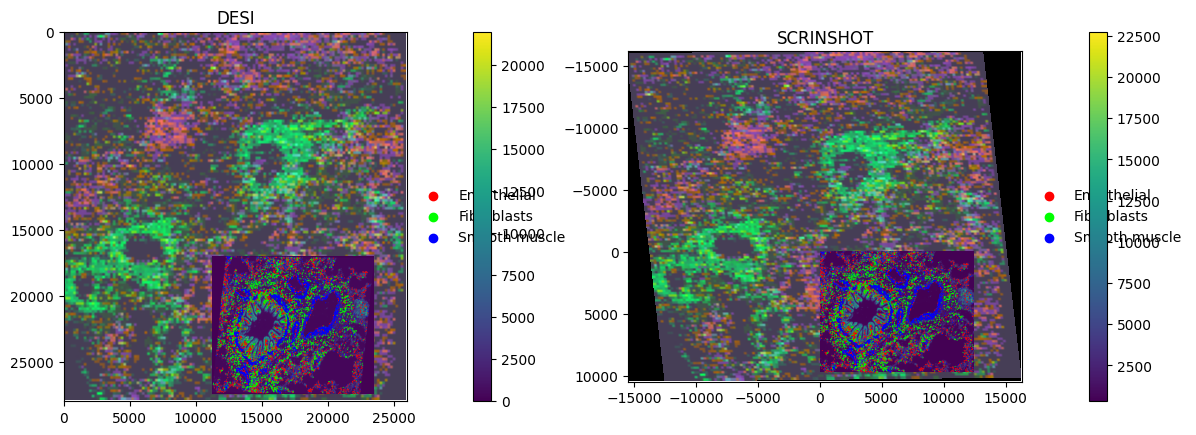

In [37]:
import spatialdata_plot
sdata["cell_types"].obs["Cell.type"] = sdata["cell_types"].obs["Cell.type"].astype("category")
# Set figure size
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 10))

sdata.pl.render_images("DESI_image").pl.render_images("hyb1_DAPI").pl.render_shapes(
    "cells", 
    color="Cell.type", 
    groups=['Endothelial','Fibroblasts','Smooth muscle'], 
    palette=['#FF0000','#00FF00','#0000FF'], 
    method="matplotlib"
).pl.show()


Visualize in Napari:

In [38]:
i = Interactive(sdata)
i.run()

Export to TissUUmaps:

In [41]:
# Get all coordinate systems:
coordinate_systems = sdata.coordinate_systems

for cs in coordinate_systems:
    print(f"Converting to TissUUmaps in coordinate system: {cs}")
    tissuumaps_helper.spatialdata_to_tissuumaps(
        sdata, 
        output_folder = "../data/output/tissuumaps",
        coordinate_system = cs
    )

Converting to TissUUmaps in coordinate system: DESI
  - Adding image hyb1_DAPI
  - Adding image DESI_image
  -Adding shape cells-large
  -Adding shape anatomical_labels
  -Adding shape cells
  -Adding table cell_types
  -Adding table DESI_obs
  -Adding points SCRINSHOT_DOT_COORDINATES
  -Adding points DESI
Converting to TissUUmaps in coordinate system: SCRINSHOT
  - Adding image hyb1_DAPI
  - Adding image DESI_image
  -Adding shape cells-large
  -Adding shape anatomical_labels
  -Adding shape cells
  -Adding table cell_types
  -Adding table DESI_obs
  -Adding points SCRINSHOT_DOT_COORDINATES
  -Adding points DESI


Save the SpatialData object to a zarr object on disk:

In [40]:
# Save the updated spatialdata object:

output_path = "../data/output/output.zarr"
sdata.write(output_path, overwrite=True)

INFO     The Zarr backing store has been changed from None the new file path: ..\data\output\output.zarr           
